# Speed-only baselines, scored with TIMSE on the eval year

Four reference models that use **only** the hourly real-time ACE speed series pulled by
`python -m training.pull_ace_rtsw`, scored by `training.evaluate` on the held-out eval year under
the rules in `docs/evaluation.md`. Each fitted model runs two ways: **frozen** (fitted once on the
training years) and **rolling** (refitted at every t0 on the last 30 days before it).

0. **Data and split.**
1. **Models**: what each baseline does.
2. **TIMSE**: pooled over the year and per forecast run, with the distribution of run scores.
3. **Predictions vs actuals**: scatter plots, error by lead and by observed speed, the TIMSE tail curve, and a fast-stream example.
4. **Residual analysis**: distribution, behaviour by lead, autocorrelation and drift.
5. **Frozen vs rolling**: head-to-head, run by run.
6. **Findings and summary.**

Every table and figure shows each fitted model in both versions, side by side. In the figures,
**colour is the model and line style is the version: dashed = frozen, solid = rolling**.
Persistence (grey) has nothing to fit, so it has a single version and serves as the reference.
In the tables, rows are indexed by (model, version).

Throughout, **residual = actual − forecast**, so a positive residual means the model under-predicted.
The headline scores can be reproduced without the notebook with `python -m training.run_baselines`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.tsa.stattools import acf

from training import run_baselines
from training.baselines import ALL, FROZEN
from training.datasets import DATA_DIR, EVAL_END, TRAIN_END, load_eval, load_hourly, load_train
from training.evaluate import HORIZON, run_forecasts, run_timse
from training.metrics import tail_mse_curve

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 1)

# Display order: the reference, then each fitted model as a (frozen, rolling) pair.
FAMILIES = list(FROZEN)  # persistence first
PAIRS = [(name, f"{name}_rolling") for name in FAMILIES if f"{name}_rolling" in ALL]
MODELS = ["persistence"] + [m for pair in PAIRS for m in pair]
assert sorted(MODELS) == sorted(ALL)

# Colour = model family, line style = version.
COLORS = {"persistence": "#8a8984", "climatology_blend": "#2a78d6",
          "recurrence_27d": "#eb6834", "autoregressive_48h": "#1baf7a"}
# Version is encoded twice, so it reads even where lines are dense:
# frozen = dashed and lighter, rolling = solid and full strength.
# Persistence is the reference: grey and dotted, so it can't be mistaken for either.
FROZEN_LS, ROLLING_LS, REFERENCE_LS = (0, (4, 2)), "-", (0, (1, 1.5))
FROZEN_ALPHA = 0.6


def family(name):
    return name.removesuffix("_rolling")


def version(name):
    if name == "persistence":
        return "reference"
    return "rolling" if name.endswith("_rolling") else "frozen"


def style(name, lw=1.6):
    """Line kwargs for a model: family colour; dashed and lighter if frozen, solid if rolling."""
    ver = version(name)
    return {"color": COLORS[family(name)], "lw": lw,
            "ls": {"frozen": FROZEN_LS, "rolling": ROLLING_LS, "reference": REFERENCE_LS}[ver],
            "alpha": FROZEN_ALPHA if ver == "frozen" else 1.0}


def by_model(table):
    """Order a model-indexed table as MODELS and index it by (model, version)."""
    # a dict maps model -> {column: value}; a DataFrame is already indexed by model
    table = pd.DataFrame(table).T if isinstance(table, dict) else pd.DataFrame(table)
    table = table.loc[[m for m in MODELS if m in table.index]]
    table.index = pd.MultiIndex.from_tuples(
        [(family(m), version(m)) for m in table.index], names=["model", "version"]
    )
    return table


def add_legend(fig, families=FAMILIES, extra=()):
    """One legend above the figure: a colour key per model, then the two line styles."""
    handles = [Line2D([], [], **style(f, lw=2)) if f == "persistence"
               else Line2D([], [], color=COLORS[f], lw=4) for f in families]
    labels = ["persistence (reference)" if f == "persistence" else f for f in families]
    handles += [Line2D([], [], color="0.45", ls=FROZEN_LS, lw=1.6, alpha=FROZEN_ALPHA),
                Line2D([], [], color="0.45", ls=ROLLING_LS, lw=1.6)]
    labels += ["frozen", "rolling (30-day refit)"]
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9, handlelength=2.6)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else f"{x:,}")

## 0. Data and split

The split dates are pinned in `training.datasets`, so the eval year never moves. Missing hours are
left as NaN: they are never fed to a model as targets, and TIMSE skips them.

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text())
series = load_hourly()
train, held_out = load_train(), load_eval()

pd.DataFrame(
    {
        "start": [train.index[0], held_out.index[0]],
        "end (exclusive)": [TRAIN_END, EVAL_END],
        "hours": [len(train), len(held_out)],
        "% missing": [100 * train.isna().mean(), 100 * held_out.isna().mean()],
        "median km/s": [train.median(), held_out.median()],
        "p99 km/s": [train.quantile(0.99), held_out.quantile(0.99)],
    },
    index=["train", "eval"],
)

,start,end (exclusive),hours,% missing,median km/s,p99 km/s
train,2021-10-20 00:00:00+00:00,2025-10-20 00:00:00+00:00,35064,6.0,421.6,721.0
eval,2025-10-20 00:00:00+00:00,2026-10-20 00:00:00+00:00,8760,1.3,446.2,758.6


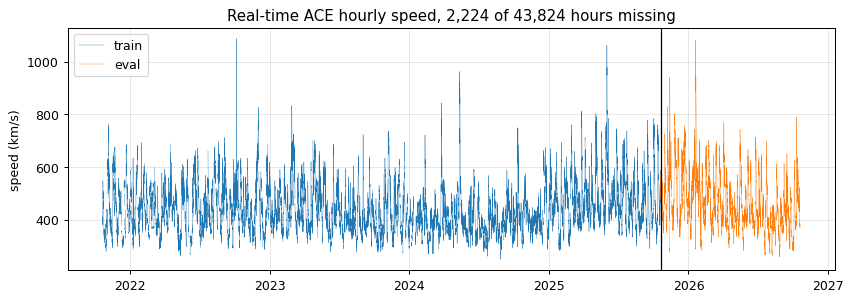

In [3]:
fig, ax = plt.subplots()
ax.plot(train.index, train, lw=0.3, color="tab:blue", label="train")
ax.plot(held_out.index, held_out, lw=0.3, color="tab:orange", label="eval")
ax.axvline(TRAIN_END, color="k", lw=1)
ax.set_ylabel("speed (km/s)")
missing, hours = manifest["missing_hours"], manifest["hours"]
ax.set_title(f"Real-time ACE hourly speed, {missing:,} of {hours:,} hours missing")
ax.legend(loc="upper left");

## 1. Models

All models are in `src/training/baselines.py`. The fitted models learn separate coefficients for
each lead hour k = 1…72, using every hour of the training years as a t0. A training sample is
dropped when its target is missing. Hyper-parameters are fixed and were not tuned on the eval year.

| Model | Forecast for t0 + k h |
|---|---|
| `persistence` | the last observed speed, for every k |
| `climatology_blend` | μ + wₖ·(last − μ). μ is the training mean; wₖ ∈ [0, 1] is fitted by least squares |
| `recurrence_27d` | aₖ + bₖ·last + cₖ·r. r is the mean speed within ±3 h of t0 + k − 27 days (one solar rotation); fitted by least squares |
| `autoregressive_48h` | Ridge regression (α = 1) on the last 48 hourly speeds |

**Rolling versions.** `Rolling(model)` refits the same model inside `predict`, at every t0, using
the hours of the last 30 days before t0 as sample t0s. Inputs may reach further back (the 48 lags,
the recurrence window one rotation earlier), and μ becomes the mean of those 30 days. A target
past the end of the history counts as missing, so short leads also learn from the newest hours.
Both versions appear in every section; section 5 compares them head to head.

**Missing inputs.** If no speed has been observed, `last` becomes μ. A recurrence window with no
data uses μ. A missing lag hour is replaced with `last`. These substitutions only affect the model
inputs; the stored data stays un-imputed.

## 2. TIMSE

`run_baselines.run()` passes each model through `training.evaluate.evaluate`. The harness fits the
model on the training years, then forecasts every 6-hourly t0 in the eval year from data observed by
t0. It reports two kinds of score:

- **Pooled TIMSE** (`timse`): every run's hours combined into one score for the year.
- **Per-run TIMSE** (`run_timse_*`): each 72-hour run scored on its own hours (its own thresholds),
  then summarised across runs. A run needs at least two observed hours to be scored.

Lower is better for both.

In [4]:
scores = run_baselines.run(ALL)
cols = ["timse", "run_timse_mean", "run_timse_median", "run_timse_std",
        "run_timse_p10", "run_timse_p90", "run_timse_max", "rmse", "n_runs_scored"]
fmt(by_model(scores.set_index("model")[cols]))

  persistence          TIMSE 8.13e+07  run TIMSE median 7.756e+05  RMSE 110.0


  climatology_blend    TIMSE 9.856e+07  run TIMSE median 4.316e+05  RMSE 91.9


  recurrence_27d       TIMSE 8.398e+07  run TIMSE median 4.119e+05  RMSE 84.4


  autoregressive_48h   TIMSE 1.043e+08  run TIMSE median 4.334e+05  RMSE 91.4


  climatology_blend_rolling TIMSE 8.37e+07  run TIMSE median 5.174e+05  RMSE 90.9


  recurrence_27d_rolling TIMSE 7.09e+07  run TIMSE median 5.697e+05  RMSE 89.7


  autoregressive_48h_rolling TIMSE 9.546e+07  run TIMSE median 5.77e+05  RMSE 94.8


timse run_timse_mean run_timse_median  \
model              version                                               
persistence        reference  8.13e+07       5.57e+06         7.76e+05   
climatology_blend  frozen     9.86e+07       5.09e+06         4.32e+05   
                   rolling    8.37e+07       4.11e+06         5.17e+05   
recurrence_27d     frozen      8.4e+07       4.29e+06         4.12e+05   
                   rolling    7.09e+07       3.75e+06          5.7e+05   
autoregressive_48h frozen     1.04e+08        5.2e+06         4.33e+05   
                   rolling    9.55e+07       4.39e+06         5.77e+05   

                             run_timse_std run_timse_p10 run_timse_p90  \
model              version                                               
persistence        reference      1.64e+07      8.33e+04      1.38e+07   
climatology_blend  frozen         1.68e+07      6.88e+04       1.1e+07   
                   rolling        1.43e+07      8.06e+04      8.29e+06   
recurrence_27d     frozen         1.48e+07      6.09e+04      8.52e+06   
                   rolling        1.28e+07      7.69e+04       6.9e+06   
autoregressive_48h frozen          1.8e+07       6.6e+04      1.06e+07   
                   rolling        1.72e+07       8.6e+04      7.59e+06   

                             run_timse_max  rmse n_runs_scored  
model              version                                      
persistence        reference      2.84e+08   110         1,448  
climatology_blend  frozen         2.47e+08  91.9         1,448  
                   rolling        2.39e+08  90.9         1,448  
recurrence_27d     frozen         2.27e+08  84.4         1,448  
                   rolling        2.21e+08  89.7         1,448  
autoregressive_48h frozen         2.77e+08  91.4         1,448  
                   rolling        3.07e+08  94.8         1,448

The cell below keeps every run's forecasts and actuals, for all seven models, for the rest of
the notebook.
`run_forecasts` is the same protocol the harness uses: fit on the training years only, then predict
each eval t0 from the hours before it (a rolling model refits on the 30 days before t0).

In [5]:
forecasts = {}
for name in MODELS:
    model = ALL[name]()
    t0s_m, forecasts[name], actual_m = run_forecasts(model)
    if name == "persistence":
        t0s, actual = t0s_m, actual_m
    assert (t0s_m == t0s).all() and np.array_equal(actual_m, actual, equal_nan=True)
    if version(name) == "rolling":
        print(f"{name}: {model.n_fallback} of {len(t0s)} runs fell back to the frozen model")
residuals = {name: actual - f for name, f in forecasts.items()}
run_scores = pd.DataFrame({name: run_timse(f, actual) for name, f in forecasts.items()}, index=t0s)

print(f"{len(t0s)} runs x {HORIZON} leads; {np.isnan(actual).sum()} actuals missing; "
      f"{run_scores.isna().any(axis=1).sum()} runs unscored")

climatology_blend_rolling: 0 of 1448 runs fell back to the frozen model


recurrence_27d_rolling: 0 of 1448 runs fell back to the frozen model


autoregressive_48h_rolling: 0 of 1448 runs fell back to the frozen model


1448 runs x 72 leads; 1344 actuals missing; 0 runs unscored


### 2.1 Distribution of per-run TIMSE

Per-run TIMSE is heavily right-skewed: most runs are quiet, and a few runs that meet a fast stream
score orders of magnitude worse. The histograms therefore use a log scale.

In [6]:
summary = run_scores.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).T
summary["skew"] = run_scores.skew()
summary["share of total from top 5% runs"] = [
    s.nlargest(int(0.05 * s.count())).sum() / s.sum() for _, s in run_scores.items()
]
summary["count"] = summary["count"].astype(int)
fmt(by_model(summary))

count      mean       std       min       10%  \
model              version                                                    
persistence        reference  1,448  5.57e+06  1.64e+07  9.39e+03  8.33e+04   
climatology_blend  frozen     1,448  5.09e+06  1.68e+07  9.92e+03  6.88e+04   
                   rolling    1,448  4.11e+06  1.43e+07  8.33e+03  8.06e+04   
recurrence_27d     frozen     1,448  4.29e+06  1.48e+07  8.74e+03  6.09e+04   
                   rolling    1,448  3.75e+06  1.28e+07  7.19e+03  7.69e+04   
autoregressive_48h frozen     1,448   5.2e+06   1.8e+07  9.38e+03   6.6e+04   
                   rolling    1,448  4.39e+06  1.72e+07  9.16e+03   8.6e+04   

                                   25%       50%       75%       90%  \
model              version                                             
persistence        reference  2.43e+05  7.76e+05  4.31e+06  1.38e+07   
climatology_blend  frozen     1.53e+05  4.32e+05   3.4e+06   1.1e+07   
                   rolling    1.97e+05  5.17e+05   2.6e+06  8.29e+06   
recurrence_27d     frozen     1.43e+05  4.12e+05   2.3e+06  8.52e+06   
                   rolling    2.05e+05   5.7e+05  2.22e+06   6.9e+06   
autoregressive_48h frozen     1.46e+05  4.33e+05  3.45e+06  1.06e+07   
                   rolling    2.07e+05  5.77e+05   2.6e+06  7.59e+06   

                                   99%       max  skew  \
model              version                               
persistence        reference  5.68e+07  2.84e+08  9.43   
climatology_blend  frozen     8.73e+07  2.47e+08  8.08   
                   rolling    6.35e+07  2.39e+08  9.35   
recurrence_27d     frozen     8.61e+07  2.27e+08  8.01   
                   rolling    6.58e+07  2.21e+08  8.74   
autoregressive_48h frozen     9.36e+07  2.77e+08  8.55   
                   rolling    8.52e+07  3.07e+08  10.5   

                             share of total from top 5% runs  
model              version                                    
persistence        reference                           0.499  
climatology_blend  frozen                              0.565  
                   rolling                             0.584  
recurrence_27d     frozen                              0.612  
                   rolling                             0.605  
autoregressive_48h frozen                              0.579  
                   rolling                             0.612

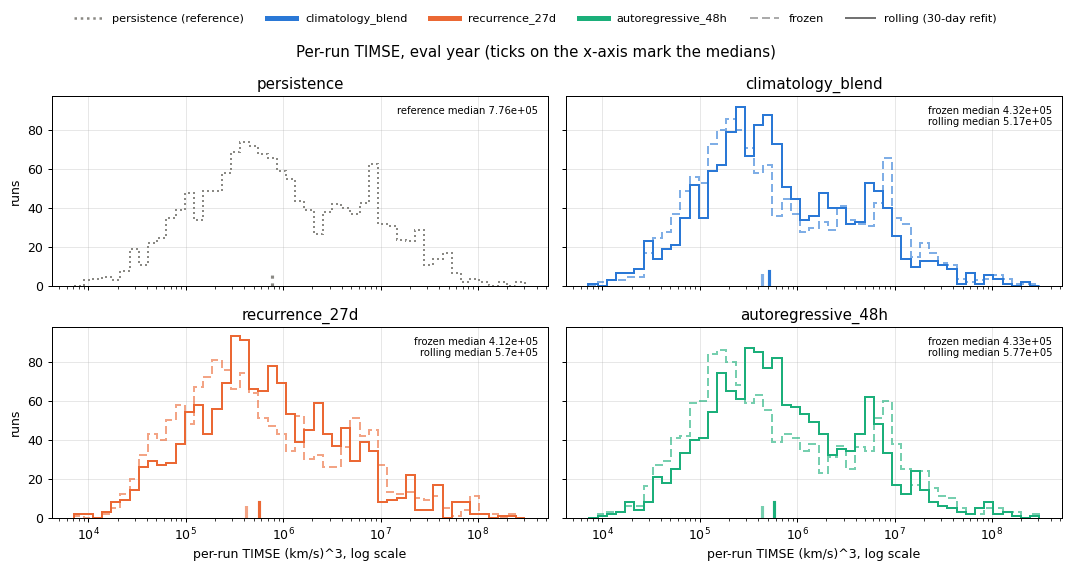

In [7]:
# One panel per model: frozen (dashed) and rolling (solid) histograms overlaid.
bins = np.logspace(np.log10(run_scores.min().min()), np.log10(run_scores.max().max()), 50)
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for ax, fam in zip(axes.flat, FAMILIES, strict=True):
    notes = []
    for name in [m for m in MODELS if family(m) == fam]:
        s = run_scores[name].dropna()
        ax.hist(s, bins=bins, histtype="step", **style(name))
        ax.axvline(s.median(), ymax=0.08, **style(name, lw=2.5))
        notes.append(f"{version(name)} median {s.median():.3g}")
    ax.text(0.98, 0.95, "\n".join(notes), transform=ax.transAxes, ha="right", va="top",
            fontsize=8)
    ax.set_xscale("log")
    ax.set_title(fam)
for ax in axes[1]:
    ax.set_xlabel("per-run TIMSE (km/s)^3, log scale")
for ax in axes[:, 0]:
    ax.set_ylabel("runs")
fig.suptitle("Per-run TIMSE, eval year (ticks on the x-axis mark the medians)")
fig.tight_layout()
add_legend(fig)

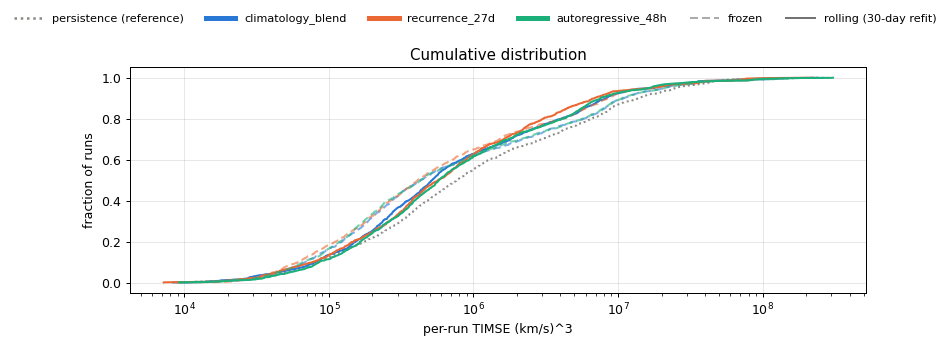

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name in MODELS:
    s = np.sort(run_scores[name].dropna())
    ax.plot(s, np.arange(1, len(s) + 1) / len(s), **style(name))
ax.set_xscale("log")
ax.set(xlabel="per-run TIMSE (km/s)^3", ylabel="fraction of runs", title="Cumulative distribution")
fig.tight_layout()
add_legend(fig)

### 2.2 Which runs win?

Head-to-head, per run: the share of runs where each model beats persistence, and the per-run
scores over the eval year, one panel per model with its frozen and rolling versions. Bad runs cluster around fast-stream arrivals.

runs beating persistence  \
model              version                            
climatology_blend  frozen                      0.64   
                   rolling                     0.65   
recurrence_27d     frozen                      0.70   
                   rolling                     0.65   
autoregressive_48h frozen                      0.65   
                   rolling                     0.61   

                           median ratio to persistence  
model              version                              
climatology_blend  frozen                         0.80  
                   rolling                        0.73  
recurrence_27d     frozen                         0.64  
                   rolling                        0.67  
autoregressive_48h frozen                         0.77  
                   rolling                        0.75

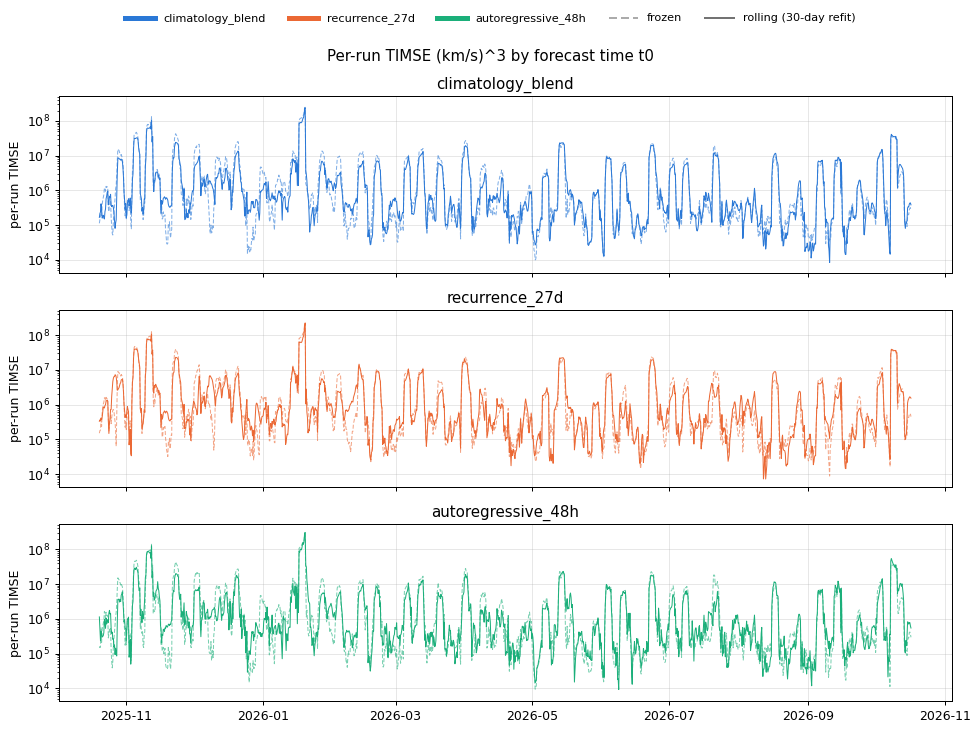

In [9]:
versus = pd.DataFrame(
    {
        name: {
            "runs beating persistence": (run_scores[name] < run_scores["persistence"]).mean(),
            "median ratio to persistence": (run_scores[name] / run_scores["persistence"]).median(),
        }
        for name in MODELS
        if name != "persistence"
    }
).T
display(by_model(versus).map("{:.2f}".format))

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(11, 2.6 * len(PAIRS)), sharex=True, sharey=True)
for ax, pair in zip(axes, PAIRS, strict=True):
    for name in pair:
        ax.plot(run_scores.index, run_scores[name], **style(name, lw=0.8))
    ax.set_yscale("log")
    ax.set(ylabel="per-run TIMSE", title=family(pair[0]))
fig.suptitle("Per-run TIMSE (km/s)^3 by forecast time t0")
fig.tight_layout()
add_legend(fig, families=[family(p[0]) for p in PAIRS])

## 3. Predictions vs actuals

### 3.1 Scatter plots

Every scored hour of every run (about 103,000 points per model), one row per model with the
frozen and rolling versions next to each other. In the two left columns, a perfect forecast lies
on the diagonal. In the two right columns, a perfect forecast lies on zero; points above zero are
under-predictions.

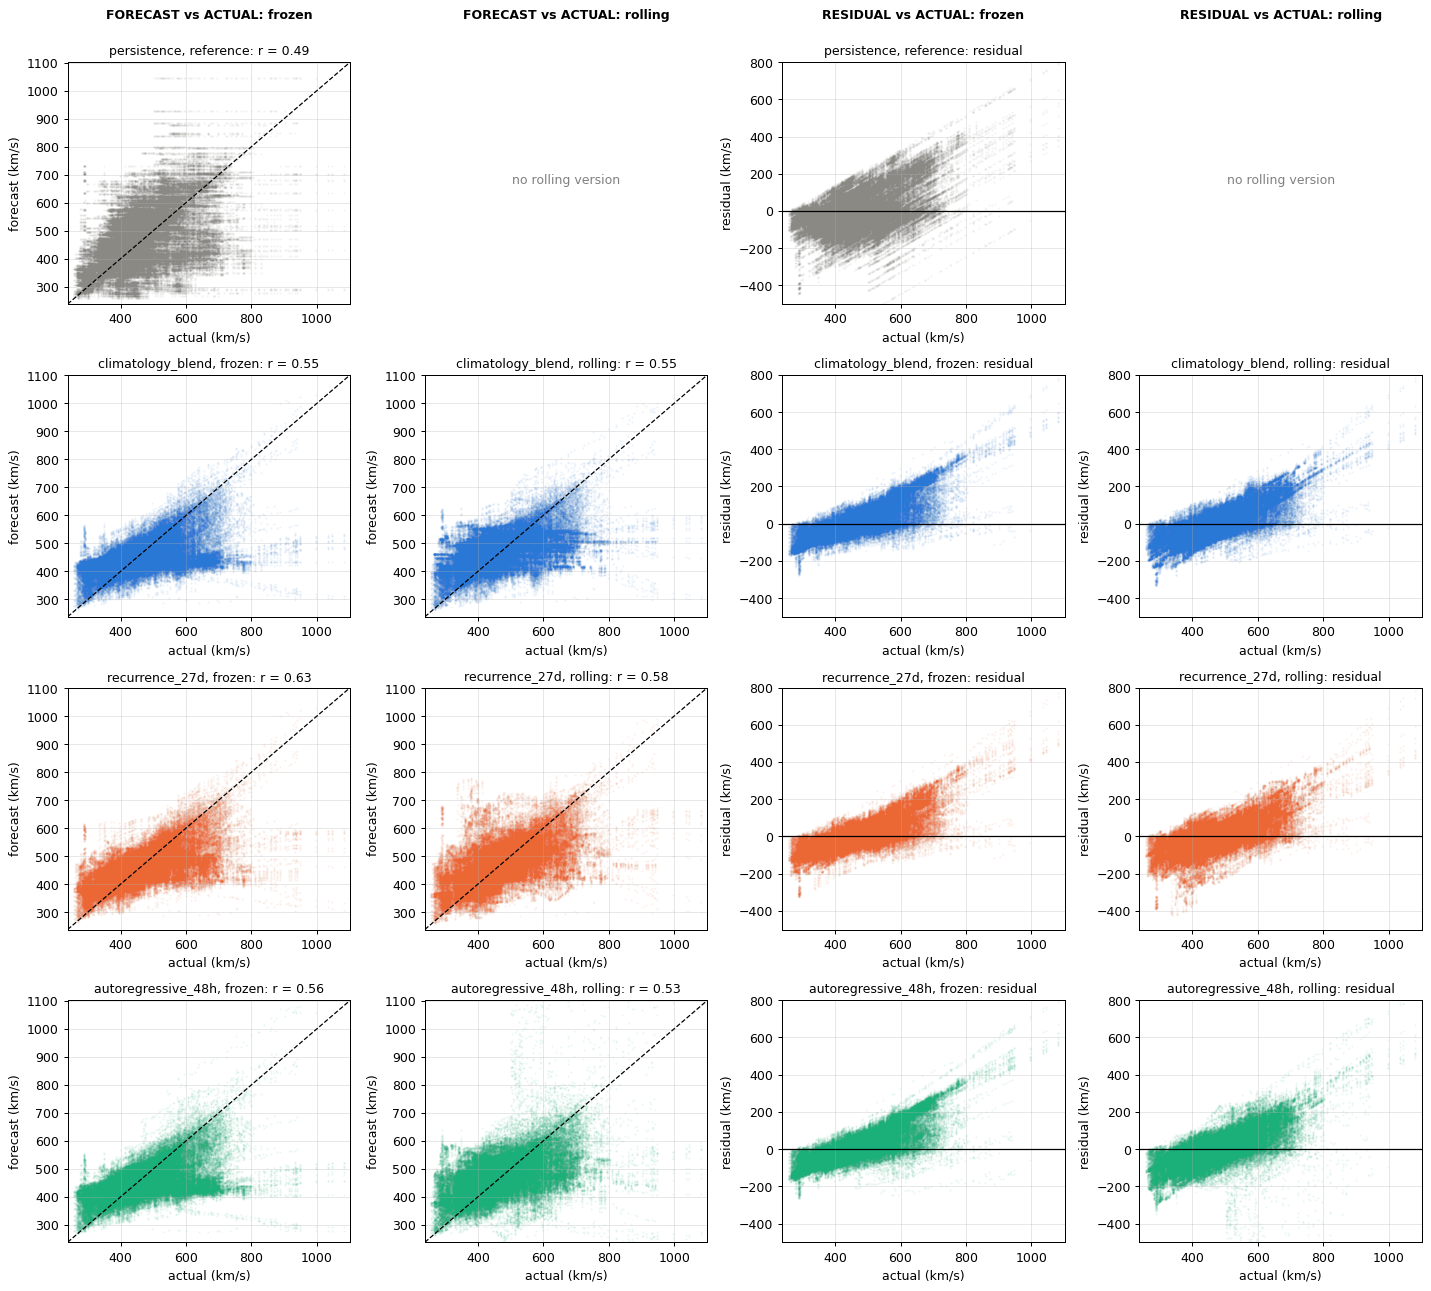

In [10]:
ok = np.isfinite(actual)
lims = (np.nanmin(actual) - 20, np.nanmax(actual) + 20)
fig, axes = plt.subplots(len(FAMILIES), 4, figsize=(16, 3.6 * len(FAMILIES)))
for row, fam in zip(axes, FAMILIES, strict=True):
    versions = {version(m): m for m in MODELS if family(m) == fam}
    for col, ver in enumerate(["frozen", "rolling"]):
        name = versions.get(ver, versions.get("reference") if ver == "frozen" else None)
        ax_f, ax_r = row[col], row[col + 2]
        if name is None:
            for ax in (ax_f, ax_r):
                ax.text(0.5, 0.5, "no rolling version", transform=ax.transAxes, ha="center",
                        color="0.5")
                ax.axis("off")
            continue
        a, f, r = actual[ok], forecasts[name][ok], residuals[name][ok]
        color = COLORS[fam]
        ax_f.scatter(a, f, s=1, alpha=0.05, color=color, rasterized=True)
        ax_f.plot(lims, lims, "k--", lw=1)
        ax_f.set(xlim=lims, ylim=lims, xlabel="actual (km/s)", ylabel="forecast (km/s)")
        ax_f.set_title(f"{fam}, {version(name)}: r = {np.corrcoef(a, f)[0, 1]:.2f}", fontsize=10)
        ax_r.scatter(a, r, s=1, alpha=0.05, color=color, rasterized=True)
        ax_r.axhline(0, color="k", lw=1)
        ax_r.set(xlim=lims, ylim=(-500, 800), xlabel="actual (km/s)", ylabel="residual (km/s)")
        ax_r.set_title(f"{fam}, {version(name)}: residual", fontsize=10)
for ax, title in zip(axes[0], ["FORECAST vs ACTUAL: frozen", "FORECAST vs ACTUAL: rolling",
                               "RESIDUAL vs ACTUAL: frozen", "RESIDUAL vs ACTUAL: rolling"],
                     strict=True):
    ax.annotate(title, (0.5, 1.18), xycoords="axes fraction", ha="center", fontweight="bold")
fig.tight_layout()

### 3.2 Error by lead time

All models start at about 22 km/s at 1 h. Persistence degrades fastest, and frozen recurrence holds
up best at long leads. Refitting only helps climatology_blend at long leads; rolling recurrence ends
level with it, well above frozen recurrence.

lead (h)                        1     6     24     48     72
model              version                                  
persistence        reference  21.7  47.7  94.8  127.7  143.4
climatology_blend  frozen     21.6  46.6  86.0  105.3  110.6
                   rolling    21.8  47.1  87.2  104.3  105.4
recurrence_27d     frozen     21.5  46.1  81.7   95.4   98.3
                   rolling    21.7  46.9  85.4  102.1  105.1
autoregressive_48h frozen     21.5  46.2  85.0  104.8  110.7
                   rolling    23.1  49.2  89.9  109.1  111.0

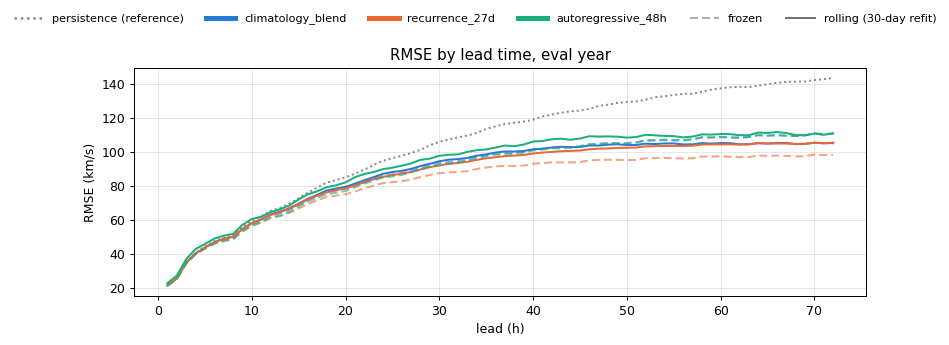

In [11]:
lead_index = pd.RangeIndex(1, HORIZON + 1, name="lead (h)")
lead_rmse = pd.DataFrame(
    {name: np.sqrt(np.nanmean(residuals[name] ** 2, axis=0)) for name in MODELS}, index=lead_index
)
fig, ax = plt.subplots(figsize=(9, 3.5))
for name in MODELS:
    ax.plot(lead_index, lead_rmse[name], **style(name))
ax.set(xlabel="lead (h)", ylabel="RMSE (km/s)", title="RMSE by lead time, eval year")
fig.tight_layout()
add_legend(fig)
by_model(lead_rmse.loc[[1, 6, 24, 48, 72]].T)

### 3.3 Error by observed speed

Mean residual and RMSE in bands of the observed speed. Every model over-predicts slow wind
(negative residual) and under-predicts fast wind (positive residual).

In [12]:
bands = [(0, 450), (450, 600), (600, 700), (700, 2000)]


def band_label(lo, hi):
    return f"{lo}-{hi}" if hi < 2000 else f">={lo}"


rows = {}
for name, r in residuals.items():
    row = {}
    for lo, hi in bands:
        sel = (actual >= lo) & (actual < hi)
        row[(band_label(lo, hi), "mean residual")] = r[sel].mean()
        row[(band_label(lo, hi), "rmse")] = np.sqrt((r[sel] ** 2).mean())
    rows[name] = row
by_speed = pd.DataFrame(rows).T
by_speed.columns = pd.MultiIndex.from_tuples(by_speed.columns)
print("points per band:", {
    band_label(lo, hi): int(((actual >= lo) & (actual < hi)).sum()) for lo, hi in bands
})
by_model(by_speed)

points per band: {'0-450': 53190, '450-600': 36282, '600-700': 10764, '>=700': 2676}


0-450             450-600         \
                             mean residual  rmse mean residual   rmse   
model              version                                              
persistence        reference         -37.0  81.0           9.2  108.1   
climatology_blend  frozen            -39.6  59.4          38.1   71.6   
                   rolling           -53.2  76.5          23.9   66.4   
recurrence_27d     frozen            -38.5  60.2          25.6   61.9   
                   rolling           -44.1  79.3          16.2   65.9   
autoregressive_48h frozen            -37.3  57.1          38.5   71.6   
                   rolling           -48.5  76.7          20.9   78.2   

                                   600-700                >=700         
                             mean residual   rmse mean residual   rmse  
model              version                                              
persistence        reference         100.7  161.9         200.8  266.3  
climatology_blend  frozen            136.9  162.0         241.5  281.9  
                   rolling           117.0  139.7         213.3  250.8  
recurrence_27d     frozen            116.6  142.7         218.1  260.3  
                   rolling           100.9  130.6         198.3  238.1  
autoregressive_48h frozen            134.7  161.5         240.3  286.3  
                   rolling           108.4  138.6         203.8  261.4

### 3.4 Why pooled TIMSE ranks the models differently from RMSE

TIMSE = Σⱼ (v*ⱼ₊₁ − v*ⱼ)·Mⱼ, where Mⱼ is the mean squared error over the hours with an observed speed
≥ v*ⱼ. In other words, TIMSE is the area under the tail-MSE curve M(v) plotted against the threshold v.
Each km/s of threshold counts equally, whether a threshold has many hours above it or only a few. The
long, sparsely populated fast tail (600 → 900+ km/s) therefore contributes a large share of the area.
`training.metrics.tail_mse_curve` returns exactly the curve that `timse` integrates.

share of scored points: {'>= 600': '13.06%', '>= 800': '0.51%', '>= 900': '0.23%'}


thresholds 0-600 thresholds 600-800  \
model              version                                         
persistence        reference         6.44e+06           1.63e+07   
climatology_blend  frozen             5.3e+06           1.82e+07   
                   rolling           4.31e+06           1.47e+07   
recurrence_27d     frozen            4.26e+06           1.59e+07   
                   rolling           3.92e+06           1.32e+07   
autoregressive_48h frozen            5.33e+06            1.9e+07   
                   rolling           4.69e+06           1.65e+07   

                             thresholds 800-900 thresholds 900-2000     TIMSE  
model              version                                                     
persistence        reference           1.56e+07            4.29e+07  8.13e+07  
climatology_blend  frozen              1.92e+07            5.58e+07  9.86e+07  
                   rolling             1.61e+07            4.86e+07  8.37e+07  
recurrence_27d     frozen              1.66e+07            4.73e+07   8.4e+07  
                   rolling             1.37e+07            4.01e+07  7.09e+07  
autoregressive_48h frozen              2.06e+07            5.93e+07  1.04e+08  
                   rolling             1.94e+07            5.48e+07  9.55e+07

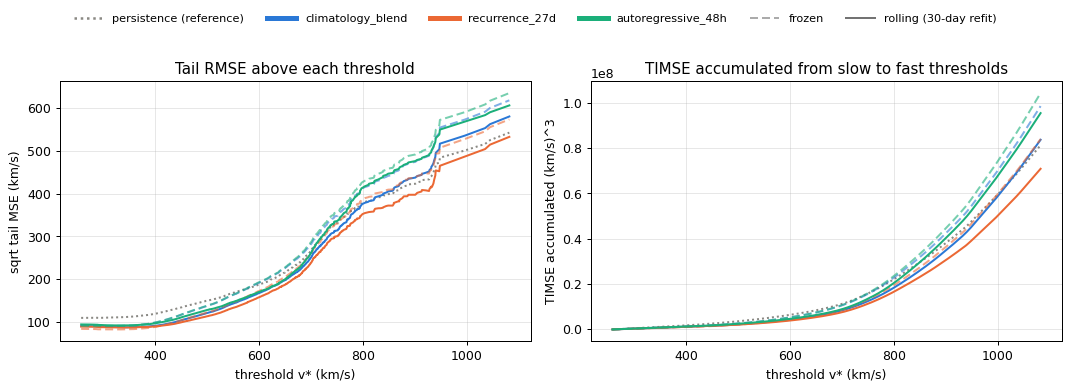

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split = {}
for name in MODELS:
    v, m = tail_mse_curve(actual, forecasts[name])  # the curve training.metrics.timse integrates
    contrib = np.diff(v) * m[:-1]  # TIMSE contribution of each threshold gap
    axes[0].plot(v, np.sqrt(m), **style(name))
    axes[1].plot(v[1:], np.cumsum(contrib), **style(name))
    split[name] = {
        f"thresholds {lo}-{hi}": contrib[(v[:-1] >= lo) & (v[:-1] < hi)].sum()
        for lo, hi in [(0, 600), (600, 800), (800, 900), (900, 2000)]
    }
    split[name]["TIMSE"] = contrib.sum()
axes[0].set(xlabel="threshold v* (km/s)", ylabel="sqrt tail MSE (km/s)")
axes[0].set_title("Tail RMSE above each threshold")
axes[1].set(xlabel="threshold v* (km/s)", ylabel="TIMSE accumulated (km/s)^3")
axes[1].set_title("TIMSE accumulated from slow to fast thresholds")
fig.tight_layout()
add_legend(fig)

observed = actual[np.isfinite(actual)]
shares = {f">= {v}": f"{(observed >= v).mean():.2%}" for v in (600, 800, 900)}
print("share of scored points:", shares)
by_model(split).map("{:.3g}".format)

### 3.5 A fast-stream example

The 48-hour-ahead forecasts around the fastest wind in the eval year, one panel per fitted model
with persistence (grey) in each for reference. Each point is the forecast made 48 h earlier for
that hour.

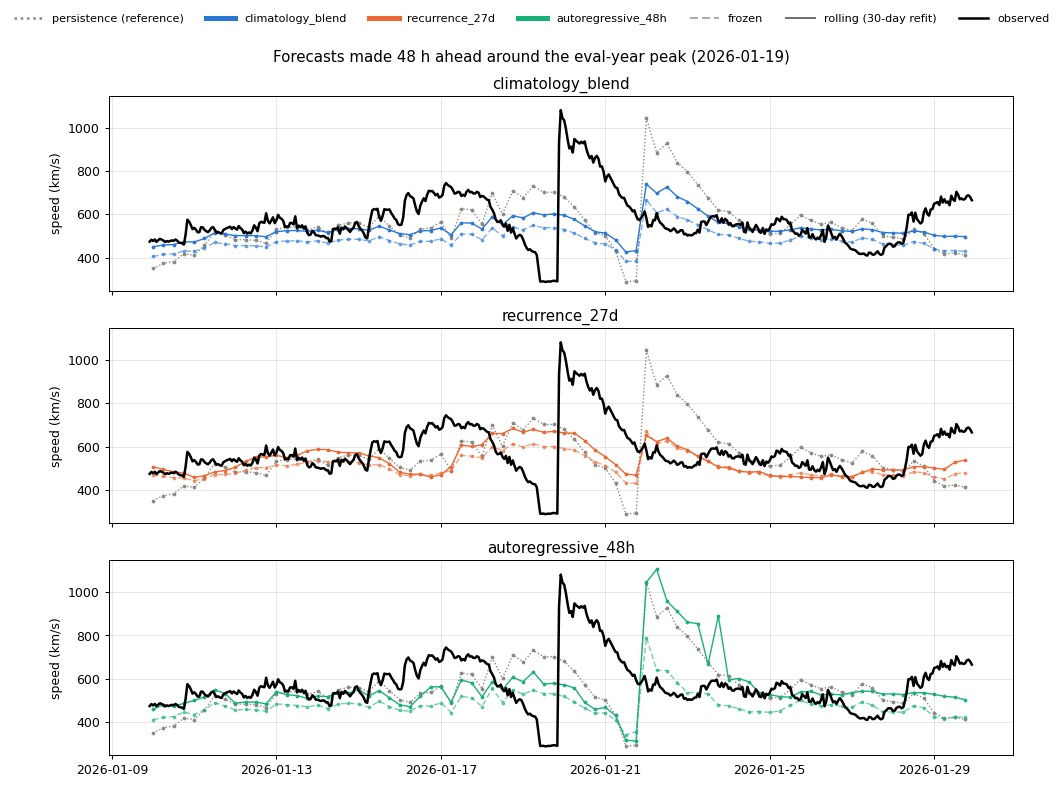

In [14]:
lead = 48
target_times = t0s + pd.Timedelta(hours=lead)
peak = held_out.idxmax()
start, end = peak - pd.Timedelta(days=10), peak + pd.Timedelta(days=10)
window = (target_times >= start) & (target_times <= end)
obs = series[start:end]

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(11, 2.8 * len(PAIRS)), sharex=True, sharey=True)
for ax, pair in zip(axes, PAIRS, strict=True):
    ax.plot(obs.index, obs, color="k", lw=2, zorder=3)
    for name in ("persistence", *pair):
        ax.plot(target_times[window], forecasts[name][window, lead - 1], marker=".", ms=4,
                **style(name, lw=1.1))
    ax.set(ylabel="speed (km/s)", title=family(pair[0]))
fig.suptitle(f"Forecasts made {lead} h ahead around the eval-year peak ({peak:%Y-%m-%d})")
fig.tight_layout()
add_legend(fig, extra=[(Line2D([], [], color="k", lw=2), "observed")])

## 4. Residual analysis

### 4.1 Distribution

A well-behaved forecast has residuals centred on zero and roughly symmetric. Positive skew means
large under-predictions (missed fast streams) are more common than large over-predictions.

mean  median     std  skew excess kurtosis  \
model              version                                                  
persistence        reference  -0.13  -13.75  109.99  0.70            1.99   
climatology_blend  frozen     13.55   -6.35   90.88  1.36            3.19   
                   rolling    -1.26  -13.38   90.86  0.95            2.54   
recurrence_27d     frozen      6.99   -8.53   84.06  1.36            4.13   
                   rolling    -1.39   -8.71   89.66  0.58            3.06   
autoregressive_48h frozen     14.66   -4.61   90.21  1.44            3.81   
                   rolling    -1.08  -10.33   94.75  0.76            3.78   

                                   p1       p5     p95     p99 share > +200  \
model              version                                                    
persistence        reference  -244.74  -153.91  210.03  310.20         0.06   
climatology_blend  frozen     -138.26   -97.59  198.60  292.80         0.05   
                   rolling    -184.97  -127.22  172.82  261.57         0.03   
recurrence_27d     frozen     -149.13   -98.20  171.60  279.62         0.03   
                   rolling    -221.49  -135.26  154.92  267.49         0.03   
autoregressive_48h frozen     -136.49   -95.81  196.39  297.33         0.05   
                   rolling    -199.50  -134.72  171.92  262.55         0.03   

                             share < -200  
model              version                 
persistence        reference         0.02  
climatology_blend  frozen            0.00  
                   rolling           0.01  
recurrence_27d     frozen            0.00  
                   rolling           0.02  
autoregressive_48h frozen            0.00  
                   rolling           0.01

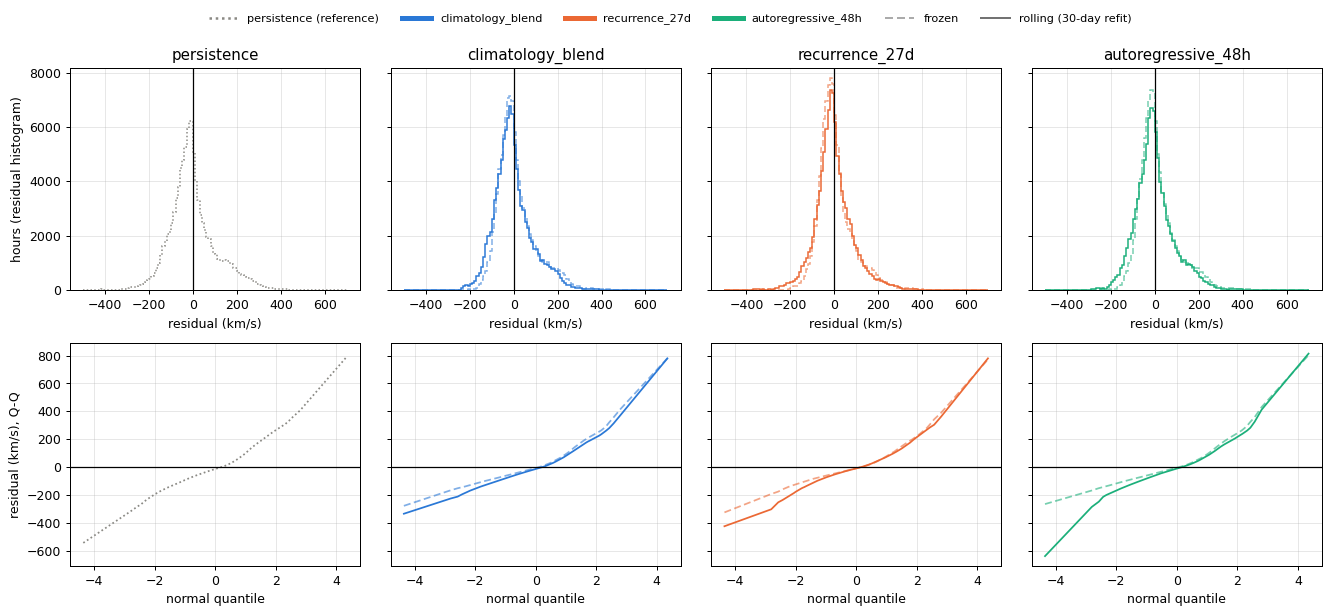

In [15]:
def residual_stats(r):
    r = r[np.isfinite(r)]
    return {
        "mean": r.mean(),
        "median": np.median(r),
        "std": r.std(),
        "skew": stats.skew(r),
        "excess kurtosis": stats.kurtosis(r),
        "p1": np.percentile(r, 1),
        "p5": np.percentile(r, 5),
        "p95": np.percentile(r, 95),
        "p99": np.percentile(r, 99),
        "share > +200": (r > 200).mean(),
        "share < -200": (r < -200).mean(),
    }


residual_table = by_model({n: residual_stats(r.ravel()) for n, r in residuals.items()})
display(residual_table.map("{:.2f}".format))

# Top row: residual histograms; bottom row: normal Q-Q plots. One column per model.
fig, axes = plt.subplots(2, len(FAMILIES), figsize=(15, 6.5), sharey="row")
edges = np.arange(-500, 701, 10)
for col, fam in enumerate(FAMILIES):
    for name in [m for m in MODELS if family(m) == fam]:
        r = residuals[name][np.isfinite(residuals[name])]
        axes[0, col].hist(r, bins=edges, histtype="step", **style(name, lw=1.2))
        (osm, osr), _ = stats.probplot(r, dist="norm")
        keep = np.linspace(0, len(osm) - 1, 400).astype(int)
        axes[1, col].plot(osm[keep], osr[keep], **style(name, lw=1.4))
    axes[0, col].axvline(0, color="k", lw=1)
    axes[0, col].set(title=fam, xlabel="residual (km/s)")
    axes[1, col].axhline(0, color="k", lw=1)
    axes[1, col].set(xlabel="normal quantile")
axes[0, 0].set_ylabel("hours (residual histogram)")
axes[1, 0].set_ylabel("residual (km/s), Q-Q")
fig.tight_layout()
add_legend(fig)

### 4.2 By lead time

The mean residual shows whether bias builds up with lead; the spread shows how fast uncertainty
grows.

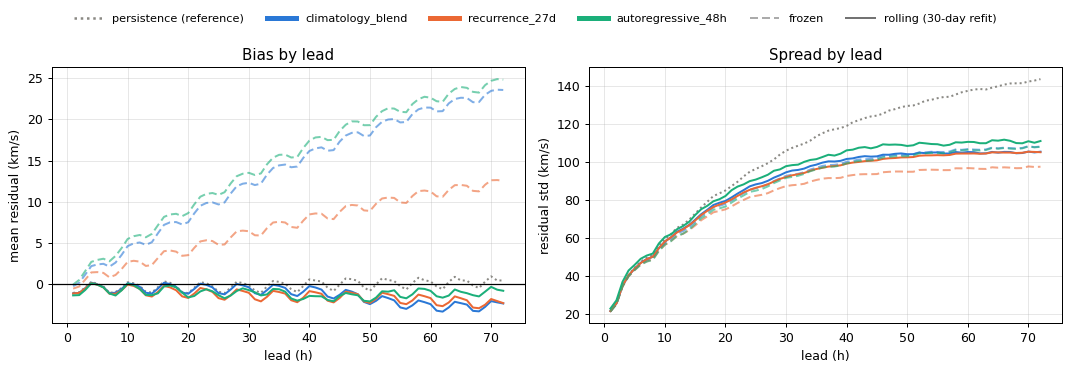

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name in MODELS:
    r = residuals[name]
    axes[0].plot(lead_index, np.nanmean(r, axis=0), **style(name))
    axes[1].plot(lead_index, np.nanstd(r, axis=0), **style(name))
axes[0].axhline(0, color="k", lw=1)
axes[0].set(xlabel="lead (h)", ylabel="mean residual (km/s)", title="Bias by lead")
axes[1].set(xlabel="lead (h)", ylabel="residual std (km/s)", title="Spread by lead")
fig.tight_layout()
add_legend(fig)

### 4.3 Autocorrelation over time

The 24-hour-ahead residual as a series over forecast times (one value every 6 h). Correlation
between successive runs is expected, since neighbouring runs forecast overlapping hours. A peak near
27 days would mean the model leaves solar-rotation structure in its errors.

1 d    3 d    7 d   14 d   27 d
model              version                                     
persistence        reference  -0.05  -0.10  -0.00  -0.09   0.21
climatology_blend  frozen      0.08  -0.06   0.02  -0.09   0.25
                   rolling     0.16  -0.09   0.01  -0.13   0.25
recurrence_27d     frozen      0.04  -0.05   0.00  -0.08   0.09
                   rolling     0.17  -0.03  -0.02  -0.09  -0.08
autoregressive_48h frozen     -0.01   0.02   0.02  -0.07   0.22
                   rolling     0.01   0.08  -0.06  -0.12   0.15

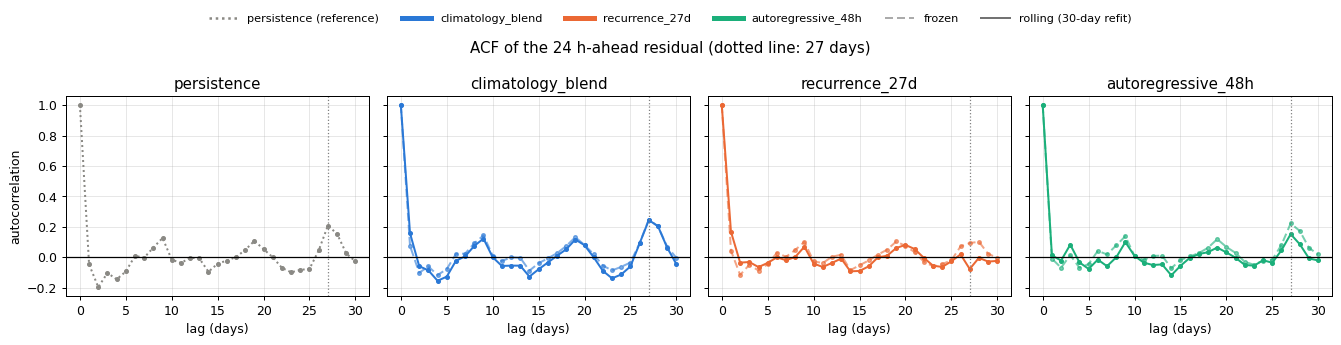

In [17]:
lag_days = np.arange(0, 31)
steps = lag_days * 4  # runs are 6 h apart
fig, axes = plt.subplots(1, len(FAMILIES), figsize=(15, 3.5), sharey=True)
acf_at = {}
for ax, fam in zip(axes, FAMILIES, strict=True):
    for name in [m for m in MODELS if family(m) == fam]:
        s = pd.Series(residuals[name][:, 23], index=t0s)
        c = acf(s.to_numpy(), nlags=steps[-1], missing="conservative")
        ax.plot(lag_days, c[steps], marker=".", **style(name))
        acf_at[name] = {f"{d} d": c[d * 4] for d in (1, 3, 7, 14, 27)}
    ax.axhline(0, color="k", lw=1)
    ax.axvline(27, color="grey", ls=":", lw=1)
    ax.set(xlabel="lag (days)", title=fam)
axes[0].set_ylabel("autocorrelation")
fig.suptitle("ACF of the 24 h-ahead residual (dotted line: 27 days)")
fig.tight_layout()
add_legend(fig)
by_model(acf_at).map("{:.2f}".format)

### 4.4 Drift over the eval year

The 27-day rolling mean of the 24-hour-ahead residual, one panel per fitted model with persistence
(grey) in each for reference. Long stretches away from zero point to
regime changes that the training years didn't cover.

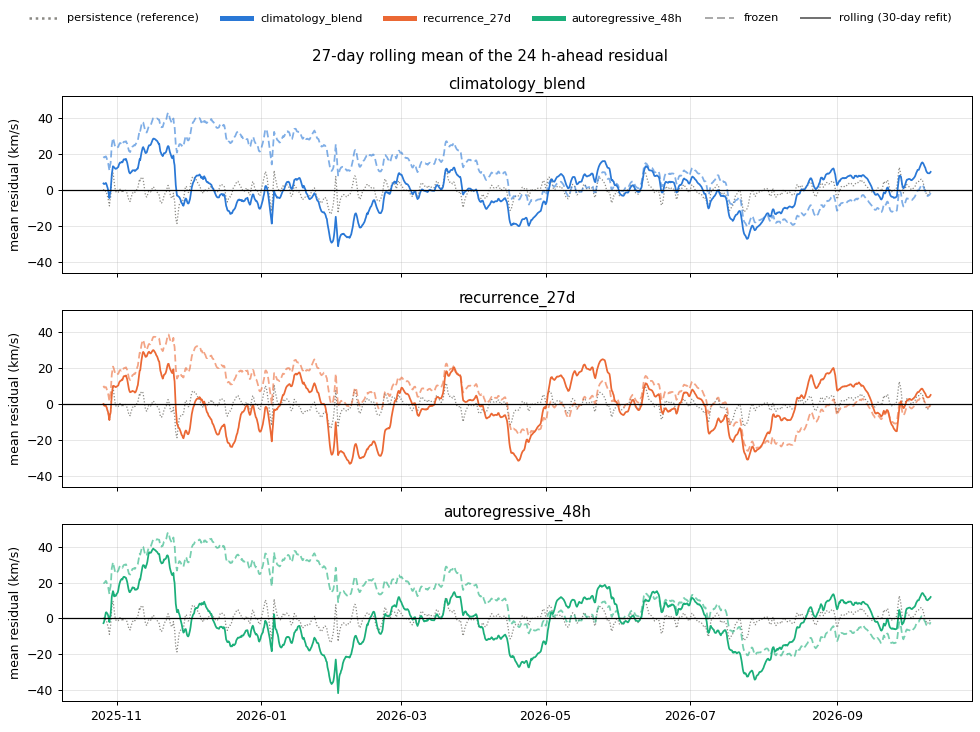

In [18]:
fig, axes = plt.subplots(len(PAIRS), 1, figsize=(11, 2.6 * len(PAIRS)), sharex=True, sharey=True)
for ax, pair in zip(axes, PAIRS, strict=True):
    for name in ("persistence", *pair):
        s = pd.Series(residuals[name][:, 23], index=t0s)
        ax.plot(s.index, s.rolling(27 * 4, center=True, min_periods=20 * 4).mean(),
                **style(name, lw=1.4 if name != "persistence" else 1.0))
    ax.axhline(0, color="k", lw=1)
    ax.set(ylabel="mean residual (km/s)", title=family(pair[0]))
fig.suptitle("27-day rolling mean of the 24 h-ahead residual")
fig.tight_layout()
add_legend(fig)

## 5. Frozen vs rolling, head to head

Frozen coefficients can't follow the change in solar-wind regime seen in section 4 (bias that grows
with lead, seasonal drift). The rolling versions refit at every t0 on the 30 days of history before
it, which a live container could do from data available at t0. The window length (30 days) and all
other hyper-parameters were fixed in advance, not tuned on the eval year.

The table puts each pair's scores next to each other, with the rolling version's change relative to
the frozen one (negative = rolling is better).

In [19]:
score_table = scores.set_index("model")
head = ["timse", "run_timse_mean", "run_timse_median", "run_timse_p90", "rmse"]
rows = {}
for frozen_name, rolling_name in PAIRS:
    fz, rl = score_table.loc[frozen_name, head], score_table.loc[rolling_name, head]
    for metric in head:
        rows[(frozen_name, metric)] = {
            "frozen": f"{fz[metric]:.3g}",
            "rolling": f"{rl[metric]:.3g}",
            "change": f"{rl[metric] / fz[metric] - 1:+.0%}",
        }
pd.DataFrame(rows).T.rename_axis(["model", "metric"]).unstack("metric").swaplevel(axis=1)[head].loc[
    [frozen_name for frozen_name, _ in PAIRS]
]

metric                 timse                  run_timse_mean                   \
                      frozen   rolling change         frozen   rolling change   
model                                                                           
climatology_blend   9.86e+07  8.37e+07   -15%       5.09e+06  4.11e+06   -19%   
recurrence_27d       8.4e+07  7.09e+07   -16%       4.29e+06  3.75e+06   -13%   
autoregressive_48h  1.04e+08  9.55e+07    -8%        5.2e+06  4.39e+06   -16%   

metric             run_timse_median                  run_timse_p90            \
                             frozen   rolling change        frozen   rolling   
model                                                                          
climatology_blend          4.32e+05  5.17e+05   +20%       1.1e+07  8.29e+06   
recurrence_27d             4.12e+05   5.7e+05   +38%      8.52e+06   6.9e+06   
autoregressive_48h         4.33e+05  5.77e+05   +33%      1.06e+07  7.59e+06   

metric                      rmse                 
                   change frozen rolling change  
model                                            
climatology_blend    -25%   91.9    90.9    -1%  
recurrence_27d       -19%   84.4    89.7    +6%  
autoregressive_48h   -29%   91.4    94.8    +4%

### 5.1 Which runs get better?

Runs are grouped by the fastest observed speed in their 72 hours. For each group: how often the
rolling model beats its frozen version, the median run TIMSE of each, and each version's total.

In [20]:
peak = pd.Series(np.nanmax(actual, axis=1), index=t0s)
groups = pd.cut(peak, [0, 500, 600, 700, np.inf], labels=["<= 500", "500-600", "600-700", "> 700"])
rows = []
for frozen_name, rolling_name in PAIRS:
    fz, rl = run_scores[frozen_name], run_scores[rolling_name]
    print(f"{rolling_name} beats {frozen_name} in {(rl < fz).mean():.0%} of runs")
    for label, idx in fz.groupby(groups, observed=True).groups.items():
        rows.append({
            "model": frozen_name, "peak km/s": label, "runs": len(idx),
            "rolling wins": f"{(rl[idx] < fz[idx]).mean():.0%}",
            "frozen median": f"{fz[idx].median():.3g}",
            "rolling median": f"{rl[idx].median():.3g}",
            "frozen total": f"{fz[idx].sum():.3g}",
            "rolling total": f"{rl[idx].sum():.3g}",
        })
pd.DataFrame(rows).set_index(["model", "peak km/s"])

climatology_blend_rolling beats climatology_blend in 52% of runs
recurrence_27d_rolling beats recurrence_27d in 48% of runs
autoregressive_48h_rolling beats autoregressive_48h in 49% of runs


runs rolling wins frozen median rolling median  \
model              peak km/s                                                   
climatology_blend  <= 500      502          33%      1.55e+05        2.3e+05   
                   500-600     349          56%      3.97e+05       3.68e+05   
                   600-700     383          63%      3.49e+06       2.58e+06   
                   > 700       214          70%      1.21e+07       7.24e+06   
recurrence_27d     <= 500      502          28%      1.55e+05       2.51e+05   
                   500-600     349          44%      3.22e+05       3.98e+05   
                   600-700     383          69%      2.49e+06       1.75e+06   
                   > 700       214          63%       8.9e+06       6.55e+06   
autoregressive_48h <= 500      502          29%      1.45e+05       2.22e+05   
                   500-600     349          54%      4.04e+05       4.15e+05   
                   600-700     383          60%      3.74e+06       2.62e+06   
                   > 700       214          71%      1.22e+07       6.63e+06   

                             frozen total rolling total  
model              peak km/s                             
climatology_blend  <= 500        9.79e+07      1.61e+08  
                   500-600       2.97e+08      2.15e+08  
                   600-700       1.76e+09      1.39e+09  
                   > 700         5.21e+09      4.18e+09  
recurrence_27d     <= 500        1.13e+08      2.83e+08  
                   500-600       1.94e+08      2.37e+08  
                   600-700       1.34e+09      1.03e+09  
                   > 700         4.57e+09      3.88e+09  
autoregressive_48h <= 500        9.24e+07      1.82e+08  
                   500-600       2.99e+08      2.26e+08  
                   600-700       1.73e+09      1.35e+09  
                   > 700          5.4e+09      4.59e+09

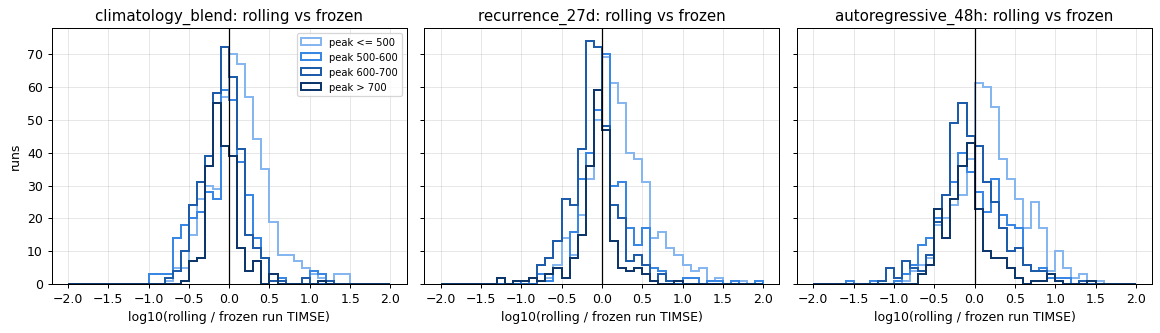

In [21]:
# Ordered groups: light (slow) to dark (fast), so they don't look like model colours.
peak_colors = dict(zip(groups.cat.categories, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
                       strict=True))
fig, axes = plt.subplots(1, len(PAIRS), figsize=(13, 3.8), sharey=True)
for ax, (frozen_name, rolling_name) in zip(axes, PAIRS, strict=True):
    ratio = np.log10(run_scores[rolling_name] / run_scores[frozen_name])
    for label in groups.cat.categories:
        ax.hist(ratio[groups == label], bins=np.linspace(-2, 2, 41), histtype="step", lw=1.6,
                color=peak_colors[label], label=f"peak {label}")
    ax.axvline(0, color="k", lw=1)
    ax.set(title=frozen_name + ": rolling vs frozen", xlabel="log10(rolling / frozen run TIMSE)")
axes[0].set_ylabel("runs")
axes[0].legend(fontsize=8)
fig.tight_layout()

### 5.2 Bias and drift

A summary of the bias and drift plotted in sections 4.2 and 4.4.

In [22]:
drift = {}
for name in MODELS:
    r = residuals[name]
    s = pd.Series(r[:, 23]).rolling(27 * 4, center=True, min_periods=20 * 4).mean()
    drift[name] = {
        "bias at 72 h": f"{np.nanmean(r[:, -1]):+.1f}",
        "residual std": f"{np.nanstd(r):.1f}",
        "drift range": f"{s.min():+.0f} to {s.max():+.0f}",
        "forecasts > 700 km/s": f"{np.mean(forecasts[name] > 700):.2%}",
    }
by_model(drift)

bias at 72 h residual std drift range  \
model              version                                           
persistence        reference         +0.5        110.0  -19 to +13   
climatology_blend  frozen           +23.6         90.9  -20 to +43   
                   rolling           -2.4         90.9  -31 to +29   
recurrence_27d     frozen           +12.5         84.1  -26 to +39   
                   rolling           -2.3         89.7  -33 to +30   
autoregressive_48h frozen           +24.8         90.2  -22 to +48   
                   rolling           -0.8         94.7  -42 to +39   

                             forecasts > 700 km/s  
model              version                         
persistence        reference                3.04%  
climatology_blend  frozen                   0.42%  
                   rolling                  0.45%  
recurrence_27d     frozen                   0.44%  
                   rolling                  0.79%  
autoregressive_48h frozen                   0.51%  
                   rolling                  0.90%

## 6. Findings

Eval year: 2025-10-20 → 2026-10-20. 1,448 forecast runs, all scorable; 102,912 hourly points scored and 1,344 skipped because the actual was missing.

Sections (i)–(iv) cover all seven models; (v) compares each frozen model with its rolling refit.

### (i) Pooled and per-run TIMSE disagree about the winner
| Model | pooled TIMSE | per-run mean | per-run median | runs beating persistence |
|---|---|---|---|---|
| persistence | 8.13 × 10⁷ | 5.57 × 10⁶ | 7.76 × 10⁵ | — |
| recurrence_27d (frozen) | 8.40 × 10⁷ | 4.29 × 10⁶ | **4.12 × 10⁵** | **70%** |
| recurrence_27d (rolling) | **7.09 × 10⁷** | **3.75 × 10⁶** | 5.70 × 10⁵ | 65% |
| climatology_blend (frozen) | 9.86 × 10⁷ | 5.09 × 10⁶ | 4.32 × 10⁵ | 64% |
| climatology_blend (rolling) | 8.37 × 10⁷ | 4.11 × 10⁶ | 5.17 × 10⁵ | 65% |
| autoregressive_48h (frozen) | 10.4 × 10⁷ | 5.20 × 10⁶ | 4.33 × 10⁵ | 65% |
| autoregressive_48h (rolling) | 9.55 × 10⁷ | 4.39 × 10⁶ | 5.77 × 10⁵ | 61% |

- **Among the frozen models, persistence wins pooled TIMSE narrowly. Run by run, it comes last on the median.** Recurrence has the lowest per-run mean and median and beats persistence in 70% of runs. Its median run scores 0.64× persistence's.
- **Rolling recurrence is the only model ahead of persistence on pooled TIMSE**, and has the best per-run mean. The rolling models beat persistence in 61–65% of runs, a little less often than their frozen versions.
- **The two views differ because pooled TIMSE builds its thresholds from the whole year.** The few hours above 900 km/s (0.23% of points, from two events: 2025-11-13 and 2026-01-19/20) set a long threshold range that only those events reach. They contribute 53% of persistence's pooled TIMSE. In per-run TIMSE, each run's thresholds come from its own 72 hours, so one event only dominates the runs that contain it.
- **Benchlab hasn't said which aggregation the leaderboard uses.** Until it does, a model should be judged on both views.

### (ii) The per-run distribution is heavy-tailed
- **Per-run TIMSE spans four orders of magnitude**, from about 10⁴ to 3 × 10⁸, with skew 8–9.
- **The worst runs carry the total.** The worst 5% of runs hold 50–61% of each model's per-run total.
- **On a log scale the histograms are bimodal.** Most runs are quiet (10⁵–10⁶), and a second group of runs that meet a fast stream sits around 10⁷.
- **Recurrence moves runs out of the bad group, more so when rolling.** Its 75th and 90th percentiles are 2.3 × 10⁶ and 8.5 × 10⁶ frozen, 2.2 × 10⁶ and 6.9 × 10⁶ rolling.
- **Refitting shifts the whole distribution.** Every rolling model has a lower p90 and p99 but a higher 10th percentile and median than its frozen version: the quiet runs get worse and the bad runs get better.
- **The bad runs line up across models.** The per-run timeline shows the same spikes for every model, because they come from the same fast-stream arrivals.

### (iii) Predictions vs actuals
- **The frozen models are pulled toward the mean.** They rarely forecast above about 700 km/s. Their residuals rise almost linearly with the actual speed: −38 km/s on average below 450 km/s, +218 to +242 km/s above 700 km/s. Recurrence has the highest correlation with the actuals (r = 0.63).
- **Persistence keeps the right spread but is often wrong in time.** Its forecasts are flat lines within a run, which show as horizontal stripes in the scatter plot. Its forecast-vs-actual correlation is the lowest (r = 0.49), and its RMSE grows fastest with lead (143 km/s at 72 h, against 98 for frozen recurrence).
- **Refitting widens the forecasts and trades one error for another.** The rolling scatter clouds reach further along the diagonal. Above 700 km/s, under-prediction shrinks to +198 to +213 km/s (from +218 to +242), but below 450 km/s over-prediction grows to −44 to −53 km/s (from −37 to −40). Correlation with the actuals falls slightly (recurrence 0.63 → 0.58), and RMSE at 72 h only improves for climatology_blend (111 → 105 km/s); rolling recurrence ends at 105 against 98 frozen.
- **The rolling gains are spread across the whole TIMSE tail.** Every threshold band in section 3.4 shrinks for every pair, by 6–19%, so the improvement doesn't hinge on the two events above 900 km/s.

### (iv) Residuals
- **The distribution is skewed toward under-prediction.**
  - The frozen models have skew 1.4 and excess kurtosis 3–4, so big misses are mostly missed fast streams.
  - Rolling roughly halves the skew (0.6–1.0) and removes the mean bias (−1.1 to −1.4 km/s), but adds large over-predictions: the 1st percentile drops to −185 to −221 km/s from −136 to −149.
  - Persistence is more symmetric (skew 0.7) but wider (std 110 against 84–91 km/s).
  - Recurrence has the fewest large under-predictions: 3% of hours more than 200 km/s too low, against 5–6% for the others.
- **The frozen models' bias grows with lead; the rolling models' doesn't.** It reaches +12 km/s (recurrence) to +25 km/s (autoregressive) at 72 h, while persistence stays at 0. The training years were slower than the eval year (median 422 against 446 km/s), so models that drift back toward the training mean under-predict. The rolling versions stay within about ±3 km/s at every lead.
- **That bias also changes with the season.** The 27-day rolling bias of the frozen models is +20 to +45 km/s in November–February and −10 to −25 km/s in July–August. The solar-wind regime shifted during the eval year, and fixed coefficients can't follow it.
- **Rotation structure is left in the errors.** The 24 h-ahead residual autocorrelates at 27 days (0.21–0.25) for persistence, climatology and autoregressive. Frozen recurrence removes most of it (0.09) and rolling recurrence all of it (−0.08). Rolling autoregressive drops to 0.15; rolling climatology_blend stays at 0.25. The rolling climatology and recurrence residuals are also more correlated from one day to the next (0.16–0.17 at 1 d, against 0.04–0.08 frozen), because neighbouring refits share most of their 30-day window. Smaller bumps near 9 and 19 days hint at several streams per rotation.
- **Sudden jumps can't be predicted from speed alone.** The 2026-01-19 jump from about 300 to 1,080 km/s was missed by every model. The dip to about 290 km/s just before it may be an artefact in the real-time data, but it is still the series the live leaderboard scores.
### (v) Rolling refit on the last 30 days
| Model | pooled TIMSE | per-run mean | per-run median | per-run p90 | RMSE | bias at 72 h |
|---|---|---|---|---|---|---|
| persistence | 8.13 × 10⁷ | 5.57 × 10⁶ | 7.76 × 10⁵ | 1.38 × 10⁷ | 110.0 | +0.5 |
| recurrence_27d (frozen) | 8.40 × 10⁷ | 4.29 × 10⁶ | **4.12 × 10⁵** | 8.52 × 10⁶ | **84.4** | +12.5 |
| recurrence_27d_rolling | **7.09 × 10⁷** | **3.75 × 10⁶** | 5.70 × 10⁵ | **6.90 × 10⁶** | 89.7 | −2.3 |
| climatology_blend_rolling | 8.37 × 10⁷ | 4.11 × 10⁶ | 5.17 × 10⁵ | 8.29 × 10⁶ | 90.9 | −2.4 |
| autoregressive_48h_rolling | 9.55 × 10⁷ | 4.39 × 10⁶ | 5.77 × 10⁵ | 7.59 × 10⁶ | 94.8 | −0.8 |

- **Rolling recurrence is the first baseline to beat persistence on pooled TIMSE** (7.09 against 8.13 × 10⁷). Every rolling model improves on its frozen version in pooled TIMSE (by 8–16%), per-run mean (by 13–19%) and per-run p90.
- **But the rolling models are worse on quiet runs, so the median and RMSE get worse.** Each rolling model beats its frozen version in only about half the runs (48–52%):
  - runs whose peak stays at or below 500 km/s: rolling wins only 28–34% of them, and their median run TIMSE rises by 50–60%;
  - runs that reach 600 km/s or more: rolling wins 60–71% of them, and their total falls by 15–23%.
  Because TIMSE is dominated by fast-wind runs, the totals improve while the typical run gets worse.
- **Why:** 30 days of samples give noisier coefficients. After a fast stream, the refit trusts the last speed more and its μ sits higher, which helps when the next stream arrives and hurts when the wind stays slow. Forecast spread at 72 h is about twice the frozen models' (std 47–73 against 21–41 km/s). Rolling recurrence and autoregressive forecast above 700 km/s about twice as often as their frozen versions.
- **The average bias goes, the seasonal drift doesn't.** Bias at 72 h falls to within ±2.5 km/s, but the 27-day rolling bias still swings by about ±30–40 km/s. A 30-day window lags regime changes by about as long as they last.
- **No fallbacks were needed.** Every eval t0 had enough observed hours in its window for a refit.
- **The window length was not tuned.** 30 days is a fixed choice. Choosing it (or blending frozen and rolling coefficients) must be done on the training years, not by comparing eval scores.

## 7. Summary

**Bottom line:** 27-day recurrence is the strongest speed-only baseline in both forms.
- **Rolling recurrence** (refitted on the last 30 days) has the best pooled TIMSE, the best per-run mean and the best per-run p90. It is the only baseline that beats persistence on pooled TIMSE.
- **Frozen recurrence** has the best per-run median and the best RMSE, the fewest large misses and the least leftover rotation structure.
- Every baseline under-predicts fast wind and misses sudden jumps.

| Area | Outcome | What it means for the next model |
|---|---|---|
| **Scoring** | Pooled TIMSE: persistence ranks first. Per-run TIMSE: recurrence ranks first, persistence last on the median. | Report both until Benchlab confirms how it aggregates. Treat a pooled TIMSE lead built on a couple of events with caution. |
| **Heavy tail** | The worst 5% of runs hold 50–61% of the per-run total. Those runs are fast-stream arrivals. | Gains come from the bad runs: forecasting fast-stream onsets and speed levels. |
| **Shrinkage** | Fitted models under-predict above 700 km/s by 218–242 km/s, and their forecasts rarely exceed about 700 km/s. | Use a tail-weighted (TIMSE-like) loss, or blend in persistence, to keep fast forecasts fast. |
| **Bias and drift** | Frozen: bias grows to +12 to +25 km/s by 72 h and swings with the season (+45 to −25 km/s). Rolling: average bias gone, seasonal swings remain. | Refit on recent data. Tune the window on the training years, and consider blending frozen and rolling coefficients to keep quiet runs stable. |
| **Frozen vs rolling** | Rolling wins fast-wind runs and loses quiet ones; it improves totals but not the typical run. | The aggregation question decides which to prefer; a shrinkage of rolling toward frozen coefficients may get both. |
| **Rotation** | Recurrence removes most of the 27-day residual structure. | Keep the recurrence input. Consider sub-rotation lags (about 9 and 13.5 days). |
| **Extremes** | CME-like jumps are missed by every model. | Add solar inputs (coronal holes, CME alerts). Speed history alone has a ceiling. |
